<a href="https://colab.research.google.com/github/R-Mishra25/customer-churn-analysis/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import drive

drive.mount('/content/drive')

# Set up standard folder paths in Google Drive
BASE_DIR = '/content/drive/MyDrive/telco_churn_analysis'
DATA_PROCESSED_DIR = os.path.join(BASE_DIR, 'data', 'processed')
REPORTS_DIR = os.path.join(BASE_DIR, 'reports', 'figures')

os.makedirs(DATA_PROCESSED_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
print("Project structure initialized at:", BASE_DIR)

Mounted at /content/drive
Project structure initialized at: /content/drive/MyDrive/telco_churn_analysis


In [2]:
import pandas as pd

# Direct CSV export link for your Google Sheet
sheet_csv_url = "https://docs.google.com/spreadsheets/d/1JQbd2LFo1ubi43SLw2xTW2v4Qk8Z_NtoD_DdQCnsegQ/export?format=csv"

# Load into pandas dataframe
df_raw = pd.read_csv(sheet_csv_url)

print(f"Dataset successfully loaded: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns")
df_raw.head()

Dataset successfully loaded: 7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
import numpy as np

def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # 1. Standardize column names to snake_case
    data.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in data.columns]

    # 2. Fix TotalCharges: blank whitespace strings coerced to NaN, then filled
    data["totalcharges"] = pd.to_numeric(data["totalcharges"], errors="coerce")
    data.loc[(data["totalcharges"].isna()) & (data["tenure"] == 0), "totalcharges"] = 0.0
    data["totalcharges"] = data["totalcharges"].fillna(data["totalcharges"].median())

    # 3. Ensure MonthlyCharges is numeric float
    data["monthlycharges"] = pd.to_numeric(data["monthlycharges"], errors="coerce").fillna(0.0)

    # 4. Standardize Churn to binary integer flag (1 = Churned, 0 = Retained)
    data["churn_flag"] = (data["churn"].astype(str).str.strip().str.lower() == "yes").astype(int)

    # 5. Clean text whitespace across categorical columns
    str_cols = data.select_dtypes(include=["object"]).columns
    for col in str_cols:
        data[col] = data[col].astype(str).str.strip().str.lower()

    return data

df_clean = clean_data(df_raw)
print("Data hygiene complete. Null values remaining:", df_clean.isna().sum().sum())

Data hygiene complete. Null values remaining: 0


In [4]:
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # 1. Lifecycle Tenure Cohorts
    bins = [-np.inf, 6, 12, 24, 48, np.inf]
    labels = ["0-6 Months", "6-12 Months", "1-2 Years", "2-4 Years", "4+ Years"]
    data["tenure_cohort"] = pd.cut(data["tenure"], bins=bins, labels=labels)

    # 2. Charge Disparity Ratio (Bill Shock indicator)
    data["avg_historical_charge"] = np.where(
        data["tenure"] > 0,
        data["totalcharges"] / data["tenure"],
        data["monthlycharges"]
    )
    data["charge_disparity_ratio"] = (
        data["monthlycharges"] / (data["avg_historical_charge"] + 1e-5)
    ).round(3)

    # 3. Product Count / Protective Services Index
    security_features = ["onlinesecurity", "techsupport", "onlinebackup", "deviceprotection"]
    data["protective_services_count"] = 0
    for col in security_features:
        if col in data.columns:
            data["protective_services_count"] += (data[col] == "yes").astype(int)

    # 4. High Monthly Spender Indicator (Top 25% percentile)
    cutoff = data["monthlycharges"].quantile(0.75)
    data["is_high_spender"] = (data["monthlycharges"] >= cutoff).astype(int)

    return data

df_processed = engineer_features(df_clean)

# Export processed dataset to Google Drive
processed_path = os.path.join(DATA_PROCESSED_DIR, "telco_churn_processed.csv")
df_processed.to_csv(processed_path, index=False)
print("Processed data exported to:", processed_path)

Processed data exported to: /content/drive/MyDrive/telco_churn_analysis/data/processed/telco_churn_processed.csv


/tmp/ipykernel_5663/1032594020.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corrs.values, y=corrs.index, palette=palette)


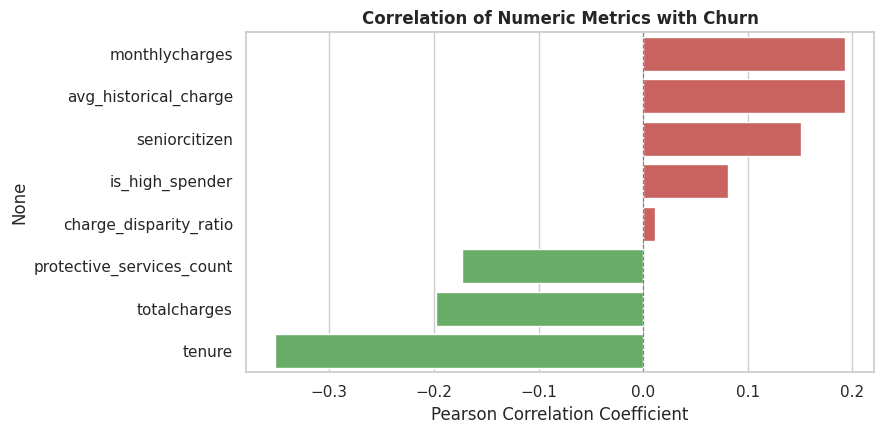

/tmp/ipykernel_5663/1032594020.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=contract_churn, x="contract", y="churn_rate_pct", palette="Blues_r")


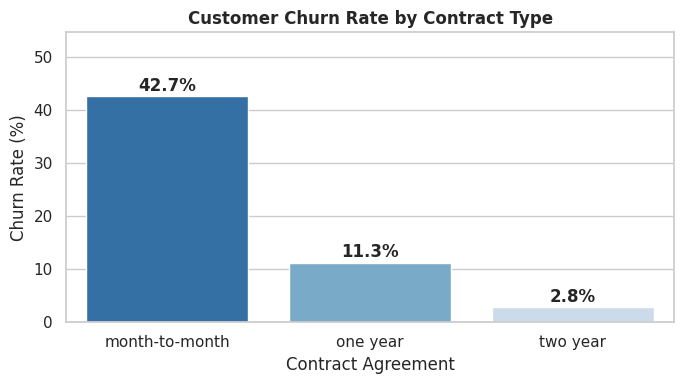

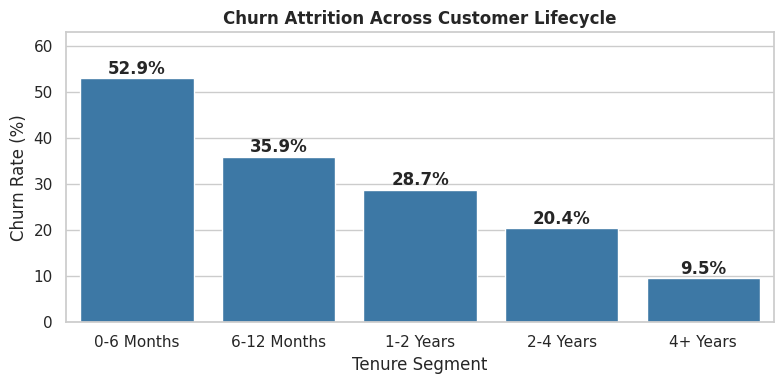

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Feature Correlations with Churn
num_cols = df_processed.select_dtypes(include=["float64", "int64", "int8"])
corrs = num_cols.corr()["churn_flag"].drop("churn_flag").sort_values(ascending=False)

plt.figure(figsize=(9, 4.5))
palette = ["#d9534f" if v > 0 else "#5cb85c" for v in corrs.values]
sns.barplot(x=corrs.values, y=corrs.index, palette=palette)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Correlation of Numeric Metrics with Churn", fontsize=12, weight="bold")
plt.xlabel("Pearson Correlation Coefficient")
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "churn_correlations.png"), dpi=300)
plt.show()

# Chart 2: Churn Rate by Contract Type
contract_churn = df_processed.groupby("contract")["churn_flag"].mean().reset_index()
contract_churn["churn_rate_pct"] = contract_churn["churn_flag"] * 100

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=contract_churn, x="contract", y="churn_rate_pct", palette="Blues_r")
plt.title("Customer Churn Rate by Contract Type", fontsize=12, weight="bold")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract Agreement")
plt.ylim(0, contract_churn["churn_rate_pct"].max() + 12)

for i, r in contract_churn.iterrows():
    ax.text(i, r["churn_rate_pct"] + 1, f"{r['churn_rate_pct']:.1f}%", ha="center", weight="semibold")

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "churn_by_contract.png"), dpi=300)
plt.show()

# Chart 3: Churn Rate by Tenure Cohort
cohort_churn = df_processed.groupby("tenure_cohort", observed=True)["churn_flag"].mean().reset_index()
cohort_churn["churn_rate_pct"] = cohort_churn["churn_flag"] * 100

plt.figure(figsize=(8, 4))
ax2 = sns.barplot(data=cohort_churn, x="tenure_cohort", y="churn_rate_pct", color="#2c7bb6")
plt.title("Churn Attrition Across Customer Lifecycle", fontsize=12, weight="bold")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Tenure Segment")
plt.ylim(0, cohort_churn["churn_rate_pct"].max() + 10)

for i, r in cohort_churn.iterrows():
    ax2.text(i, r["churn_rate_pct"] + 1, f"{r['churn_rate_pct']:.1f}%", ha="center", weight="semibold")

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "churn_by_tenure_cohort.png"), dpi=300)
plt.show()